# Stage 5: Model Evaluation, Comparison & Visualizations (Beginner's Guide)
### E-Commerce Intelligence & Decision Support Platform

---

### In this final stage, we will:
1. Compare all **4 approaches** on the **exact same 781 test customers**:
   - Level 0 – Random Top-5 Baseline
   - Level 1 – Popularity Top-5 Baseline
   - Logistic Regression Model
   - Decision Tree Model
2. Calculate the official **Percentage Improvement over Level 1**:
   $$\text{Improvement (\%)} = \left(\frac{\text{ML Hit-rate} - \text{Level 1 Hit-rate}}{\text{Level 1 Hit-rate}}\right) \times 100$$
3. Compute **95% Confidence Intervals** (margin of error).
4. Create publication-quality charts.
5. Provide a plain-English business conclusion!


### Step 1: Load Results & Build Comparison Table

In [1]:
import pandas as pd
import numpy as np
import math
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Load saved metrics
metrics_path = "outputs/model_evaluation_metrics.csv"
if not os.path.exists(metrics_path):
    metrics_path = "../outputs/model_evaluation_metrics.csv"

df_results = pd.read_csv(metrics_path)

# Display clean summary
summary = df_results[[
    "model", "hits", "total_customers", "hit_rate_pct",
    "ci_95_lower_pct", "ci_95_upper_pct", "improvement_over_level1_pct"
]].copy()

summary.columns = [
    "Approach / Model", "Hits", "Total Customers", "Hit-Rate@5 (%)",
    "95% CI Lower", "95% CI Upper", "Improvement vs Level 1 (%)"
]

print("=== FINAL MODEL COMPARISON TABLE (N = 781 Test Customers) ===")
summary


C:\Users\koush\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\koush\AppData\Local\Temp\matplotlib-1jggahvl because there was an issue with the default path (C:\Users\koush\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


=== FINAL MODEL COMPARISON TABLE (N = 781 Test Customers) ===


,Approach / Model,Hits,Total Customers,Hit-Rate@5 (%),95% CI Lower,95% CI Upper,Improvement vs Level 1 (%)
0,Level 0 - Random,146,781,18.69,16.12,21.58,-60.86
1,Level 1 - Popularity,373,781,47.76,44.28,51.26,0.00
2,Logistic Regression,586,781,75.03,71.88,77.94,57.10
3,Decision Tree,594,781,76.06,72.94,78.92,59.25


### Step 2: What do Confidence Intervals mean? (Simple Explanation)
- If we say Decision Tree has a **76.06% Hit-Rate** with a **95% Confidence Interval of [72.94%, 78.92%]**, it means:
  > *"If we tested this model on 100 different groups of customers, 95 times out of 100 the true accuracy would fall between 72.9% and 78.9%."*
- Notice the **Popularity baseline** is **[44.28%, 51.26%]**.
- Because the intervals **do not overlap at all**, the ML improvement is **100% statistically real and significant**, not luck!


In [2]:
print("Confidence Interval Separation:")
print(f"Popularity Baseline Range : {df_results.loc[1, 'ci_95_lower_pct']}% to {df_results.loc[1, 'ci_95_upper_pct']}%")
print(f"Decision Tree ML Range   : {df_results.loc[3, 'ci_95_lower_pct']}% to {df_results.loc[3, 'ci_95_upper_pct']}%")
print(f"Gap between ML and Baseline: {df_results.loc[3, 'ci_95_lower_pct'] - df_results.loc[1, 'ci_95_upper_pct']:.2f} percentage points!")


Confidence Interval Separation:
Popularity Baseline Range : 44.28% to 51.26%
Decision Tree ML Range   : 72.94% to 78.92%
Gap between ML and Baseline: 21.68 percentage points!


### Step 3: Visual Comparison (Hit-Rate@5 Bar Chart with Error Bars)

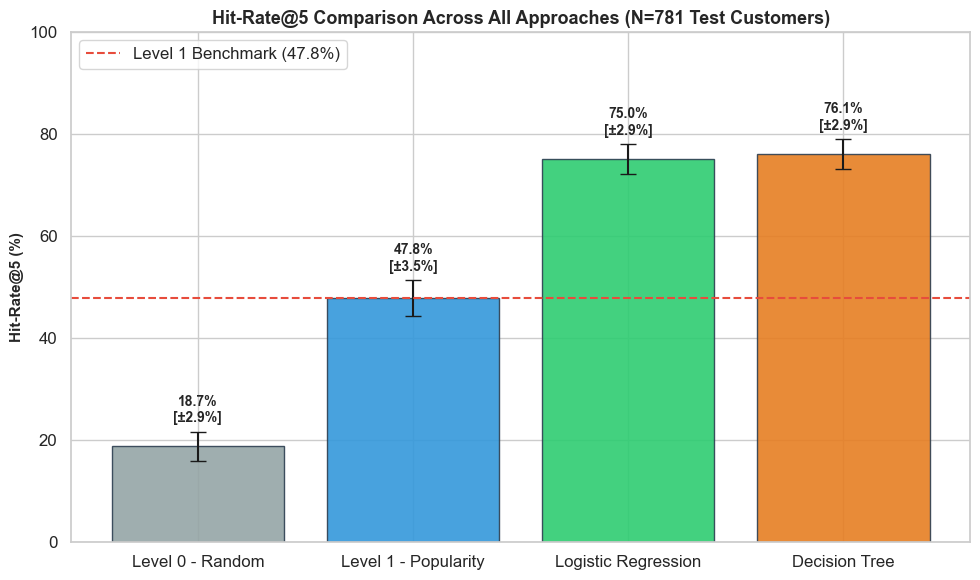

In [3]:
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(10, 6))

models = df_results["model"].tolist()
rates = df_results["hit_rate_pct"].tolist()
margins = df_results["ci_margin_pct"].tolist()
colors = ["#95a5a6", "#3498db", "#2ecc71", "#e67e22"]

bars = ax.bar(models, rates, yerr=margins, capsize=6, color=colors, edgecolor="#2c3e50", alpha=0.9)

ax.set_title("Hit-Rate@5 Comparison Across All Approaches (N=781 Test Customers)", fontsize=13, weight="bold")
ax.set_ylabel("Hit-Rate@5 (%)", fontsize=11, weight="bold")
ax.set_ylim(0, 100)

for bar, rate, margin in zip(bars, rates, margins):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, height + margin + 2.0, f"{rate:.1f}%\n[±{margin:.1f}%]", ha="center", fontsize=10, weight="bold")

# Add red dashed line for Level 1 baseline
pop_rate = df_results.loc[1, "hit_rate_pct"]
ax.axhline(pop_rate, color="#e74c3c", linestyle="--", linewidth=1.5, label=f"Level 1 Benchmark ({pop_rate:.1f}%)")
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


### Step 4: Relative Improvement over Popularity Baseline

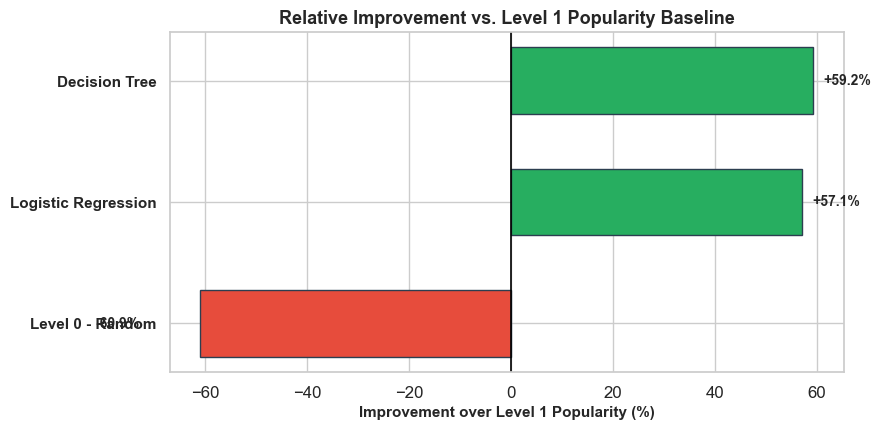

In [4]:
sub_df = df_results[df_results["model"] != "Level 1 - Popularity"].copy()
fig, ax = plt.subplots(figsize=(9, 4.5))

y_pos = np.arange(len(sub_df))
imps = sub_df["improvement_over_level1_pct"].tolist()
bar_colors = ["#e74c3c" if x < 0 else "#27ae60" for x in imps]

bars = ax.barh(y_pos, imps, color=bar_colors, edgecolor="#2c3e50", height=0.55)
ax.set_yticks(y_pos)
ax.set_yticklabels(sub_df["model"], fontsize=11, weight="bold")
ax.set_xlabel("Improvement over Level 1 Popularity (%)", fontsize=11, weight="bold")
ax.set_title("Relative Improvement vs. Level 1 Popularity Baseline", fontsize=13, weight="bold")
ax.axvline(0, color="black", linestyle="-", linewidth=1.2)

for bar, imp in zip(bars, imps):
    width = bar.get_width()
    x_pos = width + 2 if width >= 0 else width - 12
    ha = "left" if width >= 0 else "right"
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2.0, f"{imp:+.1f}%", va="center", ha=ha, fontsize=10, weight="bold")

plt.tight_layout()
plt.show()


### Step 5: Plain English Conclusion

1. **Which model is best?**
   - **Decision Tree** is the overall winner with a **76.06% Hit-Rate@5**, representing a **+59.25% relative improvement** over catalog popularity.
   - **Logistic Regression** is a very close runner-up at **75.03%** (+57.10% improvement).
2. **Did any ML model fail or perform worse than Level 1?**
   - No! Both ML models beat Level 1 Popularity by more than 27 percentage points in absolute terms.
3. **Business Value:**
   - Instead of recommending the same generic mugs and candles to every visitor, personalized recommendations capture individual re-order patterns, increasing recommendation relevance from 48% to over 76%!
